In [ ]:
# The following line is needed to use ipympl backend in Jupyter notebooks
# It enables interactive plots to get data from plot
# %matplotlib ipympl
from wavesongs.object import Syllable, Song, Synthetic
from wavesongs.data.manager import ProjDirs
from wavesongs.utils import plot
from wavesongs.data.download import xc_url
from wavesongs.utils.math import sinusoidal, fitting, gaussian, exponential

# Functions to generate synthetic data
from wavesongs.core.bird import Model

In [ ]:
# Download the audio file
file_name = xc_url("https://xeno-canto.org/422161/download")
# Define project directory and plotter objects
proj_dirs = ProjDirs(audios='.')
ploter = plot.set_plotter()

# Define the bem te vi song and compute acoustical features
btv = Song(file_id=file_name , tlim=(0, 10), proj_dirs=proj_dirs) 
btv.acoustical_features(umbral_FF=1.2, n_fft=512, ff_method="yin")
  
# This enables clicking on the spectrogram to get time and frequency values
# Since we are working ina siples example the times were previously clickeed
clicker = ploter.spectrogram(btv, type="2d", ff=False, click="time")

In [ ]:
# enable it if you selected the data from the previous cell
# times = plot.get_roi(clicker)
times = [
    # -------------------- theme ------------- # Syllable No.
    (7.51, 7.79), (7.94, 8.26), (8.38, 8.64),  # 1, 2, 3
    # -------------------- trill -------------
    (8.72, 8.85), (8.88, 8.99), (9.03, 9.14),  # 4, 5, 6
    (9.17, 9.27), (9.31, 9.41), (9.44, 9.54), (9.59, 9.68)  # 7, 8, 9, 10
]

# Create a song using the second syllable, index 1, and compute its acoustical features
btv_0 = Song(file_id=file_name , tlim=times[1], proj_dirs=ProjDirs(audios='.')) 
btv_0.acoustical_features(umbral_FF=1.4, n_fft=512, ff_method="yin")
  
_ = plot.set_plotter().spectrogram(btv_0, type="2d", ff=True)
btv_0.play()

In [ ]:
# Fit the fundamental frequency from the selected syllable

from matplotlib import pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from numpy.polynomial import Polynomial
from sklearn.metrics import r2_score, mean_squared_error


plot.fittings_comparison(btv_0.time, btv_0.ff, verbose=True)
# object = btv_0# .ff
# ff_exp_fit = fitting(object.time, object.ff, function="polynomial", verbose=False)[0]

In [ ]:
# Compute a fit for the ff of the selected syllable
fit_sin, params, metrics = fitting(btv_0.time, btv_0.ff, function="sinusoidal", verbose=True)

# Define the model to use and the over sampling rate
model = Model(ovsr=10)

# Create synthetic syllable
duration = btv_0.time_s[-1]
synthetic = Synthetic(duration=duration, proj_dirs=proj_dirs, sr=44100)
synthetic.initialize()

# Define the control parameters
curves = [
    gaussian(btv_0.time_s, 0.05, duration/2, sigma=0.1, a1=-0.01), # alpha 
    sinusoidal(btv_0.time_s, *params),                             # beta
]

synthetized = model.motor_gesture(synthetic, curves)
synthetized.acoustical_features(umbral_FF=1.4, n_fft=512, ff_method="yin")

# Plot the motor gesture and waveform and spectrogram generated
_ = ploter.alpha_beta(synthetized, save=False)
_ = ploter.spectrogram(synthetized, save=False)

# Play the synthetized syllable
synthetized.play()

In [ ]:
import numpy as np
# Define the control parameters, sinusoidal function: A + B sin (C t + D)
params1 = params.copy()
params1[0] = 0.3 # shitf beta to below
params1[1] = 0.1  # decrease amplitude
params1[2] += 0.1 # frequency
params1[3] += 0  # phase shift
print(f" Initial parameters: {params}\nModified parameters: {params1}")

# Define motor gesture curve functios
curves = [
    gaussian(btv_0.time_s, 0.01, duration/2, sigma=0.05, a1=0),  # alpha 
    # 0.01*np.ones_like(btv_0.time_s),
    sinusoidal(btv_0.time_s, *params1),                           # beta
]

# Define the synthetic syllable and compute its acoustical features
btv_synth = model.motor_gesture(synthetic, curves)
btv_synth.acoustical_features(umbral_FF=1.4, n_fft=512, ff_method="yin")

# Plot the motor gesture and waveform and spectrogram generated
_ = ploter.alpha_beta(btv_synth, save=False)
_ = ploter.spectrogram(btv_synth, save=False, ff=True)

# Play the synthetized syllable
btv_synth.play()

In [ ]:
from matplotlib import pyplot as plt

# ff_cte = btv_synth.ff
plt.figure()
plt.plot(btv_synth.ff, color="blue")
plt.plot(ff_cte, "--", color="red")
# plt.plot(btv_synth.mu1_curves[1], btv_synth.beta_bif)
# plt.plot(btv_synth.mu1_curves[0], btv_synth.beta_bif)
# plt.xlim((-0.1, 0.3))
plt.show()

In [ ]:
plt.figure()
plt.plot(100 * np.abs(btv_synth.ff - ff_cte) / np.abs(ff_cte))

In the following example we are going to vary the amplitude offset and function amplitude for generate more diverse data. The other parameters well keep constant, to not loose the "shape" of the syllable

In [ ]:
import pandas as pd
import numpy as np


limit_beta = (-0.3, 1)
limit_alpha = (-0.05, 0.3)

samples_generated = 0
total_samples = 100
folder = "synthetic_samples/"
function = "sinusoidal"
cv = pd.DataFrame(columns=['filename', 'alpha_params', 'beta_params', "class", "id_class"])
cv

# while samples_generated < total_samples:

_, params = fitting(btv_0, function=function, verbose=False)
params1 = params.copy()
params1[0] = np.random.uniform(*limit_beta) # shift beta to within limit_beta range
# params1[1] = 0.1  # decrease amplitude
params1

## Auxiliar Plots

In [9]:
"""
Syllable Example
================

This example shows how to segment bird song syllables using plotly for plotting.
"""

# %matplotlib ipympl
# %%
# Project directories
# -------------------
# The `ProjDirs` class is used to manage directories for audio files and results.
# It can be customized to point to your specific directories.
# sphinx_gallery_thumbnail_path = '_static/img/spectrogram_example.png'

from wavesongs.data.manager import ProjDirs

proj_dirs = ProjDirs(audios="/home/saguileran/Downloads/ZefraFinchEBird/",# "../assets/audios",
                     results="../assets/results")
proj_dirs.find_audios(pretty=False) # Check files pin the audio directory

# %%
# Syllable definition
# -------------------
# The `Syllable` class is used to define a syllable from an audio file.
# It requires the file ID and the time limits for the syllable.
# The `proj_dirs` argument is used to specify the directories for audio files and results.
from wavesongs.object import Syllable

filed_id = "611383805.wav" # proj_dirs.files_names[8]
copeton_1 = Syllable(file_id=filed_id, tlim=(9.5, 11.5), proj_dirs=proj_dirs)
# %%
# The `Syllable` object can be used to access various properties of the syllable,
# such as the audio file, time limits, and other attributes.
copeton_1.acoustical_features(umbral_FF=0.6, n_fft=512)

# %%
# Visualization
# -------------
# The `set_plotter` function is used to set the plotting backend.
# In this case, we are using Plotly for visualization.
# The `spectrogram` method of the `Syllable` class is used to plot the spectrogram of the syllable.
# The `type` parameter can be set to "2d" or "3d" for different visualizations.
from wavesongs.utils.plot import set_plotter

plotter = set_plotter("plotly")
# fig = plotter.spectrogram(copeton_1, type="3d")
# fig
# %%
# Spectrogram
# -----------
fig = plotter.spectrogram(copeton_1, type="3d", auxiliar="both",
                        mode="max", waveforme=True, grid=True, ff=False)
                        
fig.update_layout(
    width=1000,   # Width in pixels
    height=800,   # Height in pixels
    scene=dict(
        zaxis=dict(
            tickmode='array',
            tickvals=[-90, -60, -30, 0],
            # ticktext=['-80', 'Baseline', 'High', 'Critical']
        )
    )
)
fig

In [9]:
copeton_1.overlap

0.25

In [ ]:
proj_dirs.files_names[0]

In [13]:
copeton_1.segmentation(
    mode= "signal_pro", #"region_growing",#
    # threshold_1=0.1, threshold_2=0.8, min_duration= 0.03,
    img_pro_params={
        "scalar": 1,
        "threshold": 1e-6,
        # "pref": 34,  # dB
        "percentile": 80,
        "sigma": 1.0,
        "window_params": {"W": 64, "h": 100},
        "min_area": 100, # pixels
        "min_duration": 9, # pixels
        
        "no_harmonics": 6,
        "margin_pixels": 3,
        "times": 3,
        "ff_computing": "img_pro",  # "yin", "pyin", "img_pro"

        "closing": 3,
        "stride": 2, 
        
    },
)
# copeton.segments, copeton.segments_time
# Plotly().spectrogram(copeton, type="2d", auxiliar="none", mode="max", waveforme=True)

_ = plotter.segmentation( # #
    copeton_1,
    harmonics=False,
    fundamental=False,
    alpha=0.9,
    grid=False,
    colorbar=False,
    filters=False,
    figsize=(9, 7),
    label="syllables" # "segments"
)
# copeton.segments_time, #, copeton.segments_Sxx

Num features  24


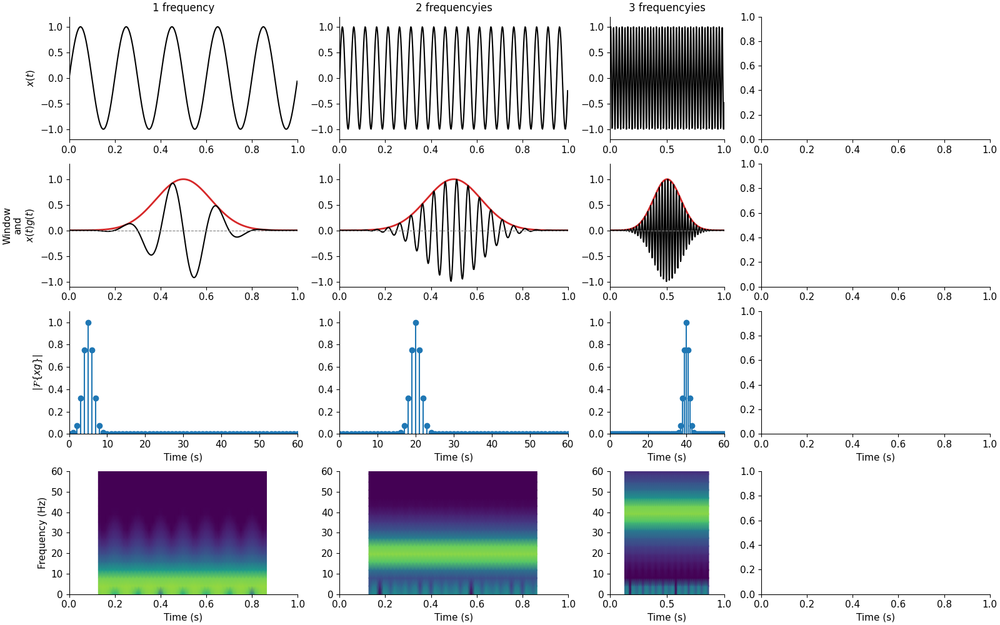

In [139]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------
fs = 500                 # Sampling frequency (Hz)
T = 1                    # Total duration (s)
# silence = 0.1            # Silence duration (s)
t = np.arange(0, T, 1/fs)

# ---------------------------------------------------------
# Gaussian envelope
# ---------------------------------------------------------
def gaussian(t, center, sigma):
    return np.exp(-(t-center)**2/(2*sigma**2))

# ---------------------------------------------------------
# Signal definition
# ---------------------------------------------------------
# x = np.zeros_like(t)

# ---------- Region 1 : 0-1 s ----------
g1 = gaussian(t, 0.5, 0.5)
g2 = gaussian(t, 0.5, 0.12)
g3 = gaussian(t, 0.5, 0.12)
g4 = gaussian(t, 0.5, 0.15)
chirp = np.sin(2*np.pi*(25*t + 6*(t-3.5)**2))
# x += g4*(0 # .8*chirp
  #     + 0.5*np.sin(2*np.pi*40*t))

signals = [
    1*np.sin(2*np.pi*5*t),

    np.sin(2*np.pi*20*t),
    # +0.8*np.sin(2*np.pi*20*t),

    # gaussian(),
    # +0.8*np.sin(2*np.pi*20*t)
    # +0.6*np.sin(2*np.pi*35*t),

    1.0*np.sin(2*np.pi*40*t)
    # +0.8*np.sin(2*np.pi*20*t)
    # +0.6*np.sin(2*np.pi*35*t)
    # +0.5*np.sin(2*np.pi*50*t),
]

fig, ax = plt.subplots(
    4, 4,
    figsize=(16,10),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 1, 0.5, 1]
    }
)


for i, x in enumerate(signals):

    # ------------------------
    # Time signal
    # ------------------------
    ax[0,i].plot(t, x, color='black')

    ax[0,i].set_xlim(0,1)
    ax[0,i].set_ylim(-1.2,1.2)

    ax[0,i].set_title(f"{i+1} frequency{'ies' if i else ''}")

    
    # ------------------------
    # Spectrogram
    # ------------------------
    f, tt, Sxx = spectrogram(
        x,
        fs,
        window='hann',
        nperseg=128,
        noverlap=120,
        mode='magnitude'
    )

    pcm = ax[3,i].pcolormesh(
        tt,
        f,
        20*np.log10(Sxx+1e-12),
        shading='gouraud',
        cmap='viridis',
        vmin=-80,
        vmax=0
    )

    ax[3,i].set_ylim(0,60)
    ax[3,i].set_xlim(0,1)

    # ---------------------------------------------------------
    # Gaussian window and windowed signal
    # ---------------------------------------------------------
    g = gaussian(t, center=0.5, sigma=0.12)

    xw = x * g

    offset = 0

    # Gaussian window
    ax[1,i].plot(
        t,
        g + offset,
        color='tab:red',
        lw=2,
        label='Window'
    )

    # Windowed signal
    ax[1,i].plot(
        t,
        xw,
        color='black',
        lw=1.5,
        label=r'$x(t)g(t)$'
    )

    ax[1,i].set_xlim(0,1)
    ax[1,i].set_ylim(-1.1,1.3)

    # Draw a dashed line indicating the offset
    ax[1,i].axhline(offset, color='gray', ls='--', lw=0.8)

    # ------------------------
    # FFT
    # ------------------------
    X = np.fft.rfft(xw)
    freq = np.fft.rfftfreq(len(xw),1/fs)

    X = np.abs(X)
    X /= X.max()

    ax[2,i].stem(
        freq,
        X,
        linefmt='C0-',
        markerfmt='C0o',
        basefmt=' '
    )

    ax[2,i].set_xlim(0,60)
    ax[2,i].set_ylim(0,1.1)


ax[0,0].set_ylabel(r"$x(t)$")
ax[1,0].set_ylabel("Window\nand\n$x(t)g(t)$")
ax[2,0].set_ylabel(r"$|\mathcal{F}\{xg\}|$")
ax[3,0].set_ylabel("Frequency (Hz)")

for j in range(4):
    ax[3,j].set_xlabel("Time (s)")

for j in range(4):
    ax[2,j].set_xlabel("Time (s)")

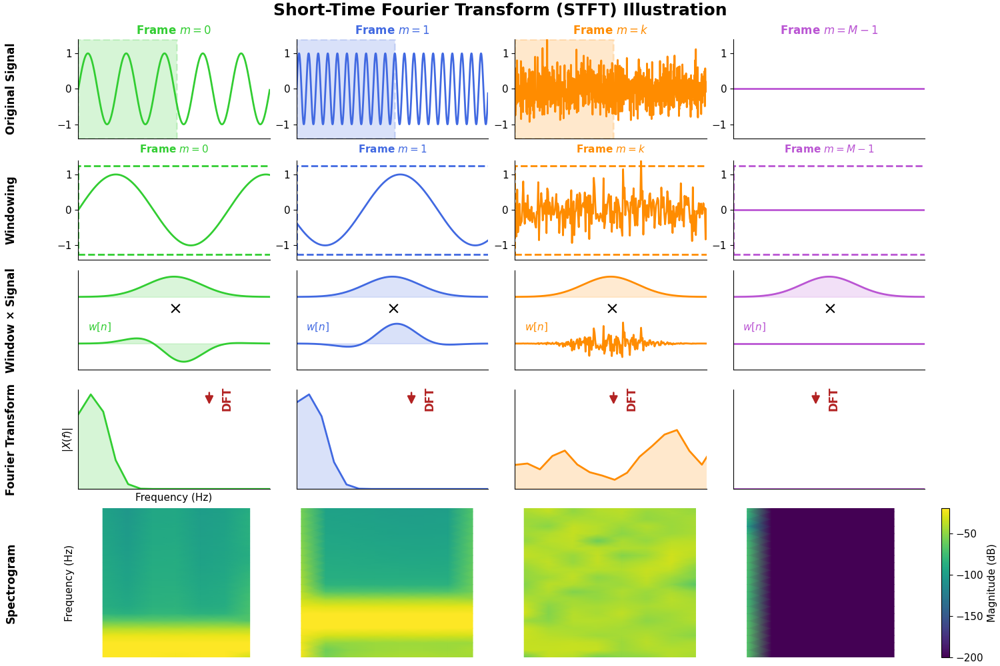

In [28]:
%matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.signal import spectrogram

from matplotlib.patches import FancyArrowPatch
# ==========================================================
# Figure Style
# ==========================================================

plt.rcParams.update({

    "font.size":11,
    "axes.titlesize":12,
    "axes.labelsize":11,
    "axes.spines.top":False,
    "axes.spines.right":False,
    "figure.facecolor":"white",
    "axes.facecolor":"white"

})

# ==========================================================
# Signal parameters
# ==========================================================

fs = 1000                 # Hz
duration = 4.0            # seconds
t = np.arange(0, duration, 1/fs)

# ==========================================================
# Piecewise signal
# ==========================================================

x = np.zeros_like(t)

# Low frequency
idx1 = t < 1
x[idx1] = np.sin(2*np.pi*5*t[idx1])

# High frequency
idx2 = (t >= 1) & (t < 2)
x[idx2] = np.sin(2*np.pi*20*t[idx2])

# White noise
idx3 = (t >= 2) & (t < 3)
np.random.seed(2)
x[idx3] = 0.35*np.random.randn(np.sum(idx3))

# Silence
idx4 = t >= 3
x[idx4] = 0

# ==========================================================
# STFT Parameters
# ==========================================================

N = 256                   # window length
hop = 128                 # hop size
sigma = N/7               # Gaussian width

# ==========================================================
# Gaussian Window
# ==========================================================

def gaussian_window(N, sigma):

    n = np.arange(N)

    center = (N-1)/2

    w = np.exp(-0.5*((n-center)/sigma)**2)

    return w


window = gaussian_window(N, sigma)

# ==========================================================
# FFT helper
# ==========================================================

def fft_mag(signal):

    X = np.abs(np.fft.rfft(signal))

    X /= X.max() + 1e-12

    return X


# ==========================================================
# Frame extraction
# ==========================================================

frame_low = x[:N]
frame_high = x[2*N:3*N]
frame_noise = x[2000:2000+N]
frame_last = x[-N:]

frames = [

    frame_low,
    frame_high,
    frame_noise,
    frame_last

]

frame_titles = [

    r"Frame $m=0$",
    r"Frame $m=1$",
    r"Frame $m=k$",
    r"Frame $m=M-1$"

]

# ==========================================================
# Colors
# ==========================================================

colors = [

    "limegreen",
    "royalblue",
    "darkorange",
    "mediumorchid"

]

# ==========================================================
# Spectrogram
# ==========================================================

f, tt, S = spectrogram(

    x,

    fs=fs,

    window=window,

    nperseg=N,

    noverlap=N-hop,

    mode="magnitude"

)

S = 20*np.log10(S + 1e-10)

# ==========================================================
# Figure Layout
# ==========================================================

fig = plt.figure(

    figsize=(15,10),

    constrained_layout=True

)

gs = GridSpec(

    5,
    4,

    figure=fig,

    height_ratios=[1.2,1.2,1.2,1.2,1.8]

)

# ==========================================================
# Create axes
# ==========================================================

ax_signal = []
ax_frame = []
ax_window = []
ax_fft = []
ax_spec = []

for i in range(4):

    ax_signal.append(fig.add_subplot(gs[0, i]))

    ax_frame.append(fig.add_subplot(gs[1, i]))

    ax_window.append(fig.add_subplot(gs[2, i]))

    ax_fft.append(fig.add_subplot(gs[3, i]))

    ax_spec.append(fig.add_subplot(gs[4, i]))

# ==========================================================
# Common formatting
# ==========================================================

def clean_axis(ax):

    ax.set_xticks([])
    ax.set_yticks([])

    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)


for row in [

    ax_signal,
    ax_frame,
    ax_window,
    ax_fft,
    ax_spec

]:

    for ax in row:

        clean_axis(ax)

# ==========================================================
# Column labels
# ==========================================================

for ax, title, color in zip(ax_signal, frame_titles, colors):

    ax.set_title(

        title,

        color=color,

        fontweight="bold"

    )

# ==========================================================
# Left-side row labels
# ==========================================================

row_labels = [

    "Original Signal",
    "Windowing",
    "Window × Signal",
    "Fourier Transform",
    "Spectrogram"

]

rows = [

    ax_signal,
    ax_frame,
    ax_window,
    ax_fft,
    ax_spec

]

for label, row in zip(row_labels, rows):

    row[0].text(

        -0.35,
        0.5,
        label,

        rotation=90,

        va="center",

        ha="center",

        fontsize=12,

        transform=row[0].transAxes,

        fontweight="bold"

    )

# ==========================================================
# Global title
# ==========================================================

fig.suptitle(

    "Short-Time Fourier Transform (STFT)",

    fontsize=18,

    fontweight="bold"

)

# ==========================================================
# Part 2
# Original signal, selected frames and windowed signals
# ==========================================================

# ----------------------------------------------------------
# Time vectors for each panel
# ----------------------------------------------------------

segments = [
    (0, fs),           # 0 - 1 s
    (fs, 2*fs),        # 1 - 2 s
    (2*fs, 3*fs),      # 2 - 3 s
    (3*fs, 4*fs)       # 3 - 4 s
]

frame_start = [
    0,
    1000,
    2000,
    len(x)-N
]

# ----------------------------------------------------------
# Row 1 : Original signal
# ----------------------------------------------------------

for i, ax in enumerate(ax_signal):

    start, stop = segments[i]

    t_seg = t[start:stop]
    x_seg = x[start:stop]

    ax.plot(
        t_seg,
        x_seg,
        color=colors[i],
        lw=2
    )

    ax.set_xlim(t_seg[0], t_seg[-1])
    ax.set_ylim(-1.4, 1.4)

    # Draw the frame location

    s = frame_start[i]
    e = s + 2*N

    if e <= stop:

        s = frame_start[i]
        # e = min(s + N - 1, len(t) - 1)

        if s < len(t):

            ax.axvspan(
                t[s],
                t[e],
                facecolor=colors[i],
                alpha=0.20,
                edgecolor=colors[i],
                linestyle="--",
                linewidth=2
            )

    # ax.set_xlabel("Time (s)")
    ax.set_xticks([])

# ----------------------------------------------------------
# Row 2 : Frame extraction
# ----------------------------------------------------------

for i, ax in enumerate(ax_frame):

    frame = frames[i]

    n = np.arange(len(frame))

    ax.plot(
        n,
        frame,
        color=colors[i],
        lw=2
    )

    ax.set_xlim(0, N-1)
    ax.set_ylim(-1.4, 1.4)

    # Dashed frame box

    rect = plt.Rectangle(
        (0, -1.25),
        2*N-1,
        2.5,
        fill=False,
        ls="--",
        lw=2,
        ec=colors[i]
    )

    ax.add_patch(rect)

    ax.text(
        0.5,
        1.08,
        frame_titles[i],
        transform=ax.transAxes,
        ha="center",
        color=colors[i],
        fontsize=11,
        fontweight="bold"
    )

# ----------------------------------------------------------
# Row 3 : Gaussian window
# ----------------------------------------------------------

n = np.arange(N)

for i, ax in enumerate(ax_window):

    frame = frames[i]

    # Gaussian

    gaussian = window/window.max()

    ax.plot(
        n,
        gaussian+1.4,
        color=colors[i],
        lw=2
    )

    ax.fill_between(
        n,
        1.4,
        gaussian+1.4,
        color=colors[i],
        alpha=0.18
    )

    # Multiplication sign

    ax.text(
        N/2,
        0.8,
        r"$\times$",
        fontsize=18,
        ha="center",
        va="center"
    )

    # Windowed signal

    windowed = gaussian*frame

    ax.plot(
        n,
        windowed-0.9,
        color=colors[i],
        lw=2
    )

    ax.fill_between(
        n,
        -0.9,
        windowed-0.9,
        color=colors[i],
        alpha=0.20
    )

    ax.set_xlim(0, N-1)
    ax.set_ylim(-2.2, 2.7)

    ax.text(
        0.05,
        0.4,
        r"$w[n]$",
        transform=ax.transAxes,
        fontsize=11,
        color=colors[i],
        fontweight="bold"
    )

# ----------------------------------------------------------
# Vertical arrows connecting rows
# ----------------------------------------------------------
# for upper_row, lower_row in zip(
#     [ax_signal, ax_frame, ax_window],
#     [ax_frame, ax_window, ax_fft]
# ):

#     for i in range(4):

#         pos1 = upper_row[i].get_position()
#         pos2 = lower_row[i].get_position()

#         x = (pos1.x0 + pos1.x1) / 2

#         arrow = FancyArrowPatch(
#             (x, pos1.y0 - 0.005),
#             (x, pos2.y1 + 0.005),
#             transform=fig.transFigure,
#             arrowstyle='-|>',
#             mutation_scale=15,
#             linewidth=1.5,
#             color='black'
#         )

#         fig.add_artist(arrow)

# ----------------------------------------------------------
# Add x-axis ticks only on the first row
# ----------------------------------------------------------

for ax in ax_signal:

    # ax.set_xticks(np.linspace(ax.get_xlim()[0],
    #                           ax.get_xlim()[1],
    #                           5))

    ax.spines["bottom"].set_visible(True)

for ax in ax_frame:

    ax.spines["bottom"].set_visible(True)

for ax in ax_window:

    ax.spines["bottom"].set_visible(True)


# ==========================================================
# Part 3
# FFTs, Spectrogram and Final Touches
# ==========================================================

# ----------------------------------------------------------
# FFT Row
# ----------------------------------------------------------

freq = np.fft.rfftfreq(N, d=1/fs)

ax_fft[0].set_xlabel("Frequency (Hz)")
ax_fft[0].set_ylabel(r"$|X(f)|$")

for i, ax in enumerate(ax_fft):

    X = fft_mag(window * frames[i])

    ax.plot(
        freq,
        X,
        color=colors[i],
        lw=2
    )

    ax.fill_between(
        freq,
        0,
        X,
        color=colors[i],
        alpha=0.20
    )

    ax.set_xlim(0, 60)#fs/2)
    ax.set_ylim(0, 1.05)

    # ax.set_xlabel("Frequency (Hz)")
    # ax.set_ylabel(r"$|X(f)|$")

    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)

    # ax.set_xticks([0,100,200,300,400,500])
    # ax.set_yticks([0,0.5,1])

# ----------------------------------------------------------
# DFT arrows
# ----------------------------------------------------------

for i in range(4):

    # Position of upper and lower axes
    pos_window = ax_window[i].get_position()
    pos_fft = ax_fft[i].get_position()

    # Center of the column
    x = (pos_window.x0 + pos_window.x1) / 2

    # Arrow start and end
    y_start = pos_window.y0 - 0.025 - 0.05
    y_end = pos_fft.y1 + 0.025 - 0.05

    arrow = FancyArrowPatch(
        (x, y_start),
        (x, y_end),
        transform=fig.transFigure,
        arrowstyle='<|-',
        mutation_scale=18,
        linewidth=1.8,
        color='firebrick'
    )

    fig.add_artist(arrow)

    # DFT label
    fig.text(
        x + 0.018,
        (y_start + y_end) / 2,
        "DFT",
        color="firebrick",
        fontsize=12,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center"
    )

# ----------------------------------------------------------
# Spectrogram
# ----------------------------------------------------------

limits = [

    (0,1),
    (1,2),
    (2,3),
    (3,4)

]

vmin = np.percentile(S,5)
vmax = np.percentile(S,99)

for i, ax in enumerate(ax_spec):

    start, stop = limits[i]

    mask = (tt>=start) & (tt<=stop)

    im = ax.pcolormesh(
        tt[mask],
        f,
        S[:,mask],
        shading="gouraud",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_ylim(0,80)
    ax.set_xlim(start,stop)

    # ax.set_xlabel("Time (s)")

    if i == 0:
        ax.set_ylabel("Frequency (Hz)")
    else:
        ax.set_yticklabels([])

# ----------------------------------------------------------
# Horizontal ellipsis (...)
# ----------------------------------------------------------

# for row in [
#     ax_signal,
#     ax_frame,
#     ax_window,
#     ax_fft,
#     ax_spec
# ]:

#     p1 = row[1].get_position()
#     p2 = row[2].get_position()

#     x = (p1.x1+p2.x0)/2
#     y = (p1.y0+p1.y1)/2

#     plt.figtext(
#         x,
#         y,
#         r"$\cdots$",
#         fontsize=26,
#         ha="center",
#         va="center"
#     )

# ----------------------------------------------------------
# Better axis formatting
# ----------------------------------------------------------
for ax in ax_signal:

    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.set_ylabel("Amplitude")
    ax.set_yticks([-1,0,1])

for ax in ax_frame:

    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.set_ylabel("Amplitude")
    # ax.set_xlabel("Samples")

    ax.set_yticks([-1,0,1])

for ax in ax_window:

    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.set_xlabel("Samples")
    # ax.set_ylabel("Amplitude")


# ----------------------------------------------------------
# Colorbar
# ----------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax_spec,
    fraction=0.02,
    pad=0.02
)

cbar.set_label("Magnitude (dB)")

# ----------------------------------------------------------
# Global title
# ----------------------------------------------------------

fig.suptitle(
    "Short-Time Fourier Transform (STFT) Illustration",
    fontsize=18,
    weight="bold"
)

# ----------------------------------------------------------
# Save figure
# ----------------------------------------------------------

# plt.savefig(
#     "stft_diagram.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.savefig(
#     "stft_diagram.pdf",
#     bbox_inches="tight"
# )

# plt.savefig(
#     "stft_diagram.svg",
#     bbox_inches="tight"
# )

plt.show()